In [81]:
import jax
jax.config.update("jax_enable_x64", True)   # must precede any jax call
import jax.numpy as jnp
import diffrax
import optimistix as optx
from scipy import constants

MP2 = 1
N_GRID = 1000            # output grid size; fixed => jit compiles once


# ---------------------------------------------------------------------------
# Radiation density (pure python floats — a compile-time constant for jit)
# ---------------------------------------------------------------------------

def omega_r(h):
    ab = (8*constants.pi**5*constants.k**4)/(15*constants.h**3*constants.c**3)
    rhor = ab*2.7255**4/(constants.c**2)
    rhov = 3.046*(7/8)*(4/11)**(4/3)*rhor
    return((rhor+rhov)/((3*(100*h)**2/(8*constants.pi*constants.G))*(1000)**2/(10**6*constants.parsec)**2))


# ---------------------------------------------------------------------------
# Early-time series solutions (initial conditions), a0-free
# ---------------------------------------------------------------------------

def aseries(tau, omega_m, h, OmL, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2)*tau)/(mups2*(-1 + \
            4*stigma))**(1/2) + (2500*h**2*tau**2*(omega_m))/(mups2) + \
            (15625*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(-2 + stigma*(5 + \
            24*stigma))*tau**3*(omega_m)**2)/(mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) + (390625*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**4*(omega_m)**3)/(2*mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val


def cpseries(tau, omega_m, h, OmL, stigma, mups2):
    val = (
       1 - (25*h*(-1 + \
            4*stigma)**(1/2)*tau*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
            4*stigma)*(2 + stigma*(-2 + \
            3*stigma))*tau**2*(omega_m)**2)/(8*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 \
            + stigma + 8*stigma**2)) + (15625*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
            stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
            + 48*stigma))))))*tau**3*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
            + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val


def aseriesp(tau, omega_m, h, OmL, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2))/(mups2*(-1 + \
            4*stigma))**(1/2) + (5000*h**2*tau*(omega_m))/(mups2) + \
            (46875*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(-2 + stigma*(5 + \
            24*stigma))*tau**2*(omega_m)**2)/(mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) + (781250*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**3*(omega_m)**3)/(mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val


def cpseriesp(tau, omega_m, h, OmL, stigma, mups2):
    # d/dtau of cpseries above: -A + 2*B*tau + 3*C*tau**2
    val = (
       - (25*h*(-1 + \
            4*stigma)**(1/2)*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
            4*stigma)*(2 + stigma*(-2 + \
            3*stigma))*tau*(omega_m)**2)/(4*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 \
            + stigma + 8*stigma**2)) + (46875*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
            stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
            + 48*stigma))))))*tau**2*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
            + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val


# ---------------------------------------------------------------------------
# The theory's ODEs (second order, conformal time), a0-free
# ---------------------------------------------------------------------------

def dda(a, da, cp, dcp, omega_m, h, OmL, stigma, mups2):
    val = (-1/8*(-(a**2*dcp**2*mups2*(3*cp**2*stigma**2 + cp**4*(1 - \
            2*stigma)**2*stigma*(-3 + 2*stigma)*(1 + 2*stigma) - stigma**3*(1 + \
            8*stigma) + cp**6*(1 - 4*stigma**2)**2)) - \
            120000*a**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma + \
            cp**2*(-1 + 4*stigma**2)) + 40000*h**2*omega_r(h)*stigma*(-cp**2 + \
            stigma)**2*(stigma + cp**2*(-1 + 4*stigma**2)) - \
            2*a*cp*da*dcp*mups2*(stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
            4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
            cp**4*(-1 + 4*stigma**2)) - cp**2*da**2*mups2*(cp**4*(1 - \
            2*stigma)**2*stigma*(-7 + 2*stigma)*(1 + 2*stigma) + stigma**3*(3 + \
            32*(-1 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            cp**2*stigma**2*(3 - 16*(-1 + stigma)*stigma*(-1 + \
            2*stigma))))/(a*cp**2*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
            4*stigma**2)))
    return val


def ddcp(a, da, cp, dcp, omega_m, h, OmL, stigma, mups2):
    val = (-1/8*(120000*a**4*h**2*OmL*stigma*(-cp**2 + \
            stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) - \
            40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + \
            cp**2*(-1 + 4*stigma**2)) + cp**2*da**2*mups2*((5 - \
            8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
            4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
            cp**4*(-1 + 4*stigma**2)) + a**2*dcp**2*mups2*(stigma**3*(-1 + \
            4*stigma)*(1 + 8*stigma) + cp**4*stigma*(-1 + 2*stigma)*(1 + \
            2*stigma)*(3 + 4*(-3 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            cp**2*stigma**2*(3 - 8*(stigma + 2*stigma**3))) + \
            2*a*cp*da*dcp*mups2*(cp**4*stigma*(-1 + 2*stigma)*(1 + \
            2*stigma)*(11 + 4*(-4 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            stigma**3*(-1 + 16*stigma*(-2 + 3*stigma)) + cp**2*stigma**2*(11 - \
            16*stigma*(1 + stigma*(-1 + \
            2*stigma)))))/(a**2*cp*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
            4*stigma**2)))
    return val


def small(omega_m, h, stigma, mups2):
    """tau_ini: small enough that the leading series term is ~1e-6 of cp."""
    return 1e-6*(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) / \
           (25*h*(-1 + 4*stigma)**(1/2)*(omega_m))


In [82]:
"""
theory_jax_noH0.py — the TorC theory with NO H0-epoch calibration.
==================================================================

Alternative anchoring to ../theory_jax.py, same interface:

    z, E, a = rhopsol_jax(omega_m, omegar, OmL, stigma, mups2)

Anchoring convention of THIS module:
    a0 = 1 is pinned in the equations, and "today" is DEFINED as the moment
    the scale factor reaches a = 1.  No reference to H0 anywhere: E(z) is
    normalised by whatever the expansion rate happens to be at a = 1.

Contrast with ../theory_jax.py (the standard convention):
    there, "today" is the epoch at which the input density fractions
    (omega_m, omegar, OmL) hold — located dynamically via the da = 100
    event (E = 1 with the labels true) — and a is normalised afterwards.

Interpretation warnings for this module:
  * omega_m / omegar / OmL are NOT today's density fractions here; they are
    the fractions at the (never-visited) epoch where H_code = 100.  Fitted
    values are not comparable to DESI's Omega_m.
  * E(z) differs from the calibrated version by a z-dependent factor that
    tends to a constant at high z (this is exactly the flat ~0.25 offset
    seen when comparing an uncalibrated a0 = 1 solve against a calibrated
    one at omega_m=0.289, OmL=0.9, stigma=1.1, mups2=3).
  * Physically, this convention ties the theory's internal a0 scale to the
    observation epoch.

Solver identical to ../theory_jax.py's tau version otherwise (diffrax,
event + steps for the tau(ln a) map, second solve on the a-grid, guarded
for sampler safety).  Self-test:  python theory_jax_noH0.py
"""

import sys, os
import jax
jax.config.update("jax_enable_x64", True)   # must precede any jax call
import jax.numpy as jnp
import diffrax
import optimistix as optx



def _a_eq_1_event():
    # "today" declared to be a = 1 in a0 = 1 units (no H0 anywhere).
    # tau state is (a, cp, da, dcp): a is y[0]
    def cond_fn(t, y, args, **kwargs):
        return y[0] - 1.0
    return diffrax.Event(cond_fn, root_finder=optx.Newton(rtol=1e-8, atol=1e-8))


def rhopsol_jax(omega_m, omegar, OmL, stigma, mups2):
    """Solve the theory with a0 = 1, today := (a = 1); return (z, E, a_norm).

    Same return convention as theory_jax.rhopsol_jax: z ascending with
    z[0] = 0, E(0) = 1 exactly, a_norm ascending and ending at 1.
    """
    tauini = small(omega_m, omegar, stigma, mups2)
    # keep t0/t1 finite even for garbage parameters (nan ICs still poison E)
    tau0 = jnp.where(jnp.isfinite(tauini) & (tauini > 0), tauini, 1e-8)
    y0 = (aseries(  tauini, omega_m, omegar, OmL, stigma, mups2),
          cpseries( tauini, omega_m, omegar, OmL, stigma, mups2),
          aseriesp( tauini, omega_m, omegar, OmL, stigma, mups2),
          cpseriesp(tauini, omega_m, omegar, OmL, stigma, mups2))
    args = (omega_m, omegar, OmL, stigma, mups2)

    # --- solve 1: integrate to a = 1, keeping the accepted steps (they
    # provide the tau(ln a) map for the output grid) --------------------------
    sol_ev = diffrax.diffeqsolve(
        _TERM_TAU, _SOLVER, t0=tau0, t1=tau0 + TAU_SPAN, dt0=0.01 * tau0,
        y0=y0, args=args, stepsize_controller=_CTRL, event=_a_eq_1_event(),
        saveat=diffrax.SaveAt(t0=True, steps=True),
        max_steps=8192,   # ample for good solves; caps the cost of FAILED ones
        throw=False,      # failed solve -> inf/nan output, not a crash (sampler-safe)
    )
    a_st, _, da_st, _ = sol_ev.ys
    mask    = jnp.isfinite(sol_ev.ts) & jnp.isfinite(a_st) & (a_st > 0)
    idx     = jnp.maximum(jnp.sum(mask) - 1, 0)
    taustar = sol_ev.ts[idx]
    astar   = a_st[idx]                        # = 1 when the event fired
    dastar  = da_st[idx]                       # H(a=1) in code units
    x0        = jnp.log(a_st[0])               # = ln a_ini (t0 is saved)
    xstar_raw = jnp.log(astar)                  # ~ 0

    # failed solve, event never reached, or a pathological corner: substitute
    # a valid dummy grid and poison E (one bad particle must not crash a
    # vmapped batch — same guard as the parent module).
    ok = (jnp.isfinite(taustar) & jnp.isfinite(xstar_raw) & jnp.isfinite(x0)
          & (jnp.abs(astar - 1.0) < 1e-3)                # event really fired
          & (dastar > 0)
          & (xstar_raw > x0 + jnp.log(1.0 + Z_SPLIT)))
    xstar = jnp.where(ok, xstar_raw, x0 + 45.0)

    # log-spaced a-grid ending exactly today: sparse before z = Z_SPLIT,
    # dense after (that's where the BAO data are)
    xsplit = xstar - jnp.log(1.0 + Z_SPLIT)
    xs = jnp.concatenate([
        jnp.linspace(x0, xsplit, N_EARLY, endpoint=False),
        jnp.linspace(xsplit, xstar, N_LATE),
    ])
    lna_st = jnp.where(mask, jnp.log(jnp.where(mask, a_st, 1.0)), xstar_raw)
    tau_st = jnp.where(mask, sol_ev.ts, taustar)
    tau_targets = jnp.interp(xs, lna_st, tau_st)
    dummy = tau0 * (1.0 + jnp.linspace(0.0, 1.0, N_EARLY + N_LATE))
    tau_targets = jnp.where(ok, tau_targets, dummy)
    tau_end     = jnp.where(ok, taustar, 2.0 * tau0)

    # --- solve 2: same trajectory, saved on the a-grid -----------------------
    sol = diffrax.diffeqsolve(
        _TERM_TAU, _SOLVER, t0=tau0, t1=tau_end, dt0=0.01 * tau0, y0=y0,
        args=args, stepsize_controller=_CTRL,
        saveat=diffrax.SaveAt(ts=tau_targets),
        max_steps=8192,
        throw=False,
    )
    a_ev, cp_ev, da_ev, dcp_ev = sol.ys

    a_norm = a_ev / astar                        # = 1 today (a = 1)
    z      = 1.0 / a_norm - 1.0
    # E = H/H(a=1) with H = da/a^2 in a0 = 1 code units — no "100" anywhere
    E      = (da_ev / dastar) * (astar / a_ev) ** 2
    E      = jnp.where(ok, E, jnp.nan)   # failed solve -> nan -> logL floor

    return z[::-1], E[::-1], a_norm


# ===========================================================================
# self-test:  python theory_jax_noH0.py
# ===========================================================================
if __name__ == "__main__":
    import numpy as np
    from scipy.integrate import solve_ivp
    from test_theory_cpr1 import (aseries as aseries_s, cpseries as cpseries_s,
                                  aseriesp as aseriesp_s, cpseriesp as cpseriesp_s,
                                  coupdiff, small as small_s)
    from theory_jax import rhopsol_jax as rhopsol_calibrated

    h_cmp   = 0.7
    omegar_ = omega_r(h_cmp)

    # reference: the UNCALIBRATED scipy solve (a0 = 1, stop at a = 1) — the
    # construction used in stigma/jupyter/Jax-Copy1.ipynb
    def rhopsol_scipy_a0eq1(omega_m, h, OmL, stigma, mups2):
        tauini = small_s(omega_m, h, stigma, mups2)
        y0 = [aseries_s(tauini, omega_m, h, OmL, 1, stigma, mups2),
              cpseries_s(tauini, omega_m, h, OmL, 1, stigma, mups2),
              aseriesp_s(tauini, omega_m, h, OmL, 1, stigma, mups2),
              cpseriesp_s(tauini, omega_m, h, OmL, 1, stigma, mups2)]
        def astop(t, y): return y[0] - 1.0
        astop.terminal = True
        rhs = lambda t, y: coupdiff(y, t, omega_m, h, OmL, 1, stigma, mups2)
        sol = solve_ivp(rhs, [tauini, np.inf], y0, events=astop,
                        rtol=1e-8, atol=1e-8)
        # t_eval pass on a log-spaced a-grid (as in the notebook's 3-pass code)
        from scipy.interpolate import interp1d
        tsol  = interp1d(sol.y[0], sol.t, bounds_error=False)
        avals = np.logspace(np.log10(sol.y[0][0]), 0, 5000)
        tvals = tsol(avals); tvals[0] = tauini
        sol2 = solve_ivp(rhs, [tauini, np.inf], y0, t_eval=tvals,
                         events=astop, rtol=1e-8, atol=1e-8)
        a, cp, da, dcp = sol2.y
        aend, _, daend, _ = sol2.y_events[0][0]
        H = da / a**2
        z = 1/a - 1
        return z, H / (daend / aend**2)         # E normalised at a = 1

    print(f"{'omega_m':>8} {'stigma':>8} {'mups2':>6} {'OmL':>6} | "
          f"{'noH0 vs scipy(a0=1)':>20} {'noH0 vs calibrated':>19}")
    for om, sg, mp, ol in [(0.28929, 1.1,    3.0, 0.9),      # the notebook case
                           (0.2969,  1.0001, 4/3, 0.7028),
                           (0.2969,  1.5,    4/3, 0.7028),
                           (0.5,     2.0,    0.6, 1.2)]:
        zj, Ej, _ = rhopsol_jax(om, omegar_, ol, sg, mp)
        zc, Ec, _ = rhopsol_calibrated(om, omegar_, ol, sg, mp)
        zs, Es    = rhopsol_scipy_a0eq1(om, h_cmp, ol, sg, mp)
        ztest = np.linspace(0.0, 2.6, 200)
        Ej_i = np.interp(ztest, np.asarray(zj), np.asarray(Ej))
        Ec_i = np.interp(ztest, np.asarray(zc), np.asarray(Ec))
        Es_i = np.interp(ztest, zs[::-1], Es[::-1])
        print(f"{om:8.4f} {sg:8.4f} {mp:6.3f} {ol:6.3f} | "
              f"{np.max(np.abs(Ej_i/Es_i-1)):20.2e} "
              f"{np.max(np.abs(Ej_i/Ec_i-1)):19.2e}")
    print("\ncolumn 1 should be ~1e-6 (same model, jax vs scipy);")
    print("column 2 is the PHYSICAL difference between the two anchorings.")


ModuleNotFoundError: No module named 'test_theory_cpr1'

In [68]:
h = 0.7
H0 = 100*h
stigma = 1.1
mups2 = 3
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2
OmL = 0.9
c_kms = 299792.458  # km/s
omegar = omega_r(h)

z_jax, H_jax, a_jax = rhopsol_jax(omega_m, h, OmL, stigma, mups2)

In [69]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy import constants
import matplotlib.pyplot as plt
import camb
MP2 = 1

def omega_r(h):
    ab = (8*constants.pi**5*constants.k**4)/(15*constants.h**3*constants.c**3)
    rhor = ab*2.7255**4/(constants.c**2)
    rhov = 3.046*(7/8)*(4/11)**(4/3)*rhor
    return((rhor+rhov)/((3*(100*h)**2/(8*constants.pi*constants.G))*(1000)**2/(10**6*constants.parsec)**2))

def aseries(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2)*tau)/(a0**2*mups2*(-1 + \
            4*stigma))**(1/2) + (2500*h**2*tau**2*(omega_m))/(a0*mups2) + \
            (15625*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(-2 + stigma*(5 + \
            24*stigma))*tau**3*(omega_m)**2)/(a0*mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) + (390625*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**4*(omega_m)**3)/(2*a0*mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def cpseries(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
       1 - (25*h*(-1 + \
            4*stigma)**(1/2)*tau*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
            4*stigma)*(2 + stigma*(-2 + \
            3*stigma))*tau**2*(omega_m)**2)/(8*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 \
            + stigma + 8*stigma**2)) + (15625*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
            stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
            + 48*stigma))))))*tau**3*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
            + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def cpseriesp(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (-25*h*(-1 + \
        4*stigma)**(1/2)*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
        4*stigma)*(2 + stigma*(-2 + \
        3*stigma))*tau*(omega_m)**2)/(4*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 + \
        stigma + 8*stigma**2)) + (46875*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
        stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
        + 48*stigma))))))*tau**2*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
        + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def aseriesp(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2))/(a0**2*mups2*(-1 + \
            4*stigma))**(1/2) + (5000*h**2*tau*(omega_m))/(a0*mups2) + \
            (46875*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(-2 + stigma*(5 + \
            24*stigma))*tau**2*(omega_m)**2)/(a0*mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) + (781250*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**3*(omega_m)**3)/(a0*mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

    
def P_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    return((MP2*(10000*cp**9*da*h**2*(-1 + 4*stigma**2)**3*(4*a**4*a0**4*OmL + \
            mups2*omega_r(h) + a*a0*(omega_m)) + 2*a*dcp*stigma**3*(-1 + 2*stigma)*(1 + \
            2*stigma)*(-7 + 4*stigma)*(a**2*a0**2*dcp**2*mups2 + \
            40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + \
            2*a*cp**6*dcp*(1 - 4*stigma**2)**2*(a**2*a0**2*dcp**2*mups2*(1 - \
            4*stigma**2) + 40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + \
            a*a0*(omega_m))) - 2*a*cp**2*dcp*stigma**2*(-1 + \
            4*stigma**2)*(-(a**2*a0**2*dcp**2*mups2*(5 + 8*stigma*(1 + 2*(-2 + \
            stigma)*stigma))) + 40000*h**2*stigma*(-5 + 2*stigma)*(1 + \
            2*stigma)*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + \
            2*a*cp**4*dcp*stigma*(-(a**2*a0**2*dcp**2*mups2*(3 + 4*(-3 + \
            stigma)*stigma)*(1 - 4*stigma**2)**2) - 120000*h**2*stigma*(-1 + \
            2*stigma)*(1 + 2*stigma)*(-1 + 4*stigma)*(a**4*a0**4*OmL + omega_r(h) + \
            a*a0*(omega_m))) + cp*da*stigma**3*(-(a**2*a0**2*dcp**2*mups2*(-1 + \
            2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-19 + 8*stigma))) - \
            10000*h**2*stigma*(-5 + 8*stigma)*(8*a**4*a0**4*OmL*(-1 + stigma)*(1 + \
            2*stigma) + 4*omega_r(h)*(3 + 2*stigma*(-5 + 2*stigma)) + a*a0*(-7 + \
            4*stigma)*(-1 + 4*stigma)*(omega_m))) - cp**7*da*(1 - \
            4*stigma**2)**2*(3*a**2*a0**2*dcp**2*mups2*(-1 + 4*stigma**2) + \
            10000*h**2*stigma*(4*a**4*a0**4*OmL*(-11 + 2*stigma*(9 + stigma)) + \
            omega_r(h)*(4 - 8*(-1 + stigma)*stigma + mups2*(-11 + 4*stigma*(4 + stigma))) \
            - 4*a*a0*(2 + (-6 + stigma)*stigma)*(omega_m))) + \
            cp**3*da*stigma**2*(10000*h**2*omega_r(h)*stigma*(-92 - mups2*(5 - \
            8*stigma)**2*(-1 + 4*stigma**2) + 8*stigma*(21 + stigma*(69 + \
            4*stigma*(-41 + 18*stigma)))) + a*a0*(a*a0*dcp**2*mups2*(-1 + \
            2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-1 + stigma*(-31 + 12*stigma))) \
            + 40000*h**2*stigma*(a**3*a0**3*OmL*(37 + 2*stigma*(-67 + 7*stigma*(9 \
            + 4*stigma - 8*stigma**2))) + (-2 + 5*stigma)*(4 + stigma*(11 + \
            8*stigma*(-5 + 2*stigma)))*(omega_m)))) + cp**5*da*stigma*(-1 + \
            4*stigma**2)*(10000*h**2*omega_r(h)*stigma*(mups2*(-5 + 8*stigma)*(-7 + \
            8*stigma*(1 + stigma)) - 4*(9 + 2*stigma*(1 + 2*stigma*(-13 + \
            8*stigma)))) + a*a0*(3*a*a0*dcp**2*mups2*(1 - 16*(stigma - \
            4*stigma**3 + stigma**4)) + 20000*h**2*stigma*(2*a**3*a0**3*OmL*(37 + \
            2*stigma*(-57 + 4*stigma*(9 + 4*stigma))) + (5 - 2*stigma*(30 + \
            stigma*(-57 + \
            16*stigma)))*(omega_m))))))/(a**4*cp**3*da*mups2*(-cp**2 + \
            stigma)*(-1 + 4*stigma**2)*((5 - 8*stigma)*stigma + cp**2*(-1 + \
            4*stigma**2))**2))
    
def rho_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    return((3*MP2*(-10000*h**2*omega_r(h) - 10000*a*h**2*(omega_m) + \
            (-(a**2*a0**2*dcp**2*mups2*(-stigma + cp**2*(1 - 4*stigma**2))) - \
            2*a*a0**2*cp*da*dcp*mups2*(stigma*(-1 + 4*stigma) + cp**2*(1 - \
            4*stigma**2)) + 40000*h**2*stigma*(-cp**2 + stigma)*(a**4*a0**4*OmL \
            + omega_r(h) + a*a0*(omega_m)))/(-(cp**2*mups2*(5 - 8*stigma)*stigma) - \
            cp**4*mups2*(-1 + 4*stigma**2))))/a**4)


def ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (-1/8*(120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + \
            stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) - \
            40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + \
            cp**2*(-1 + 4*stigma**2)) + a0**2*cp**2*da**2*mups2*((5 - \
            8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
            4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
            cp**4*(-1 + 4*stigma**2)) + a**2*a0**2*dcp**2*mups2*(stigma**3*(-1 + \
            4*stigma)*(1 + 8*stigma) + cp**4*stigma*(-1 + 2*stigma)*(1 + \
            2*stigma)*(3 + 4*(-3 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            cp**2*stigma**2*(3 - 8*(stigma + 2*stigma**3))) + \
            2*a*a0**2*cp*da*dcp*mups2*(cp**4*stigma*(-1 + 2*stigma)*(1 + \
            2*stigma)*(11 + 4*(-4 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            stigma**3*(-1 + 16*stigma*(-2 + 3*stigma)) + cp**2*stigma**2*(11 - \
            16*stigma*(1 + stigma*(-1 + \
            2*stigma)))))/(a**2*a0**2*cp*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
            4*stigma**2)))
    return val

def dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (-1/8*(-(a**2*a0**2*dcp**2*mups2*(3*cp**2*stigma**2 + cp**4*(1 - \
            2*stigma)**2*stigma*(-3 + 2*stigma)*(1 + 2*stigma) - stigma**3*(1 + \
            8*stigma) + cp**6*(1 - 4*stigma**2)**2)) - \
            120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma + \
            cp**2*(-1 + 4*stigma**2)) + 40000*h**2*omega_r(h)*stigma*(-cp**2 + \
            stigma)**2*(stigma + cp**2*(-1 + 4*stigma**2)) - \
            2*a*a0**2*cp*da*dcp*mups2*(stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
            4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
            cp**4*(-1 + 4*stigma**2)) - a0**2*cp**2*da**2*mups2*(cp**4*(1 - \
            2*stigma)**2*stigma*(-7 + 2*stigma)*(1 + 2*stigma) + stigma**3*(3 + \
            32*(-1 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
            cp**2*stigma**2*(3 - 16*(-1 + stigma)*stigma*(-1 + \
            2*stigma))))/(a*a0**2*cp**2*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
            4*stigma**2)))
    return val

def coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2):
    a, cp, da, dcp = y
    dydt = [da, dcp, dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2), ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2)]
    return dydt

#Initial conditions
def small(omega_m, h, stigma, mups2):
    val = 1e-6*(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2))/(25*h*(-1 + 4*stigma)**(1/2)*(omega_m))
    return val

#Stops for Solve_ivp
def hstop(h):
    def event(t, y):
        return y[2]-h*100
    event.terminal = True
    event.direction = 1
    return event

def astop(t, y):
    return y[0]-1

astop.terminal = True
astop.direction = 1

def rhopsol(omega_m, h, OmL, stigma, mups2):

    tauini = small(omega_m, h, stigma, mups2)
    print(tauini)

    a0 = 1
    
    y02 = [aseries(tauini, omega_m, h, OmL, a0, stigma, mups2), cpseries(tauini, omega_m, h, OmL, a0, stigma, mups2),
          aseriesp(tauini, omega_m, h, OmL, a0, stigma, mups2), cpseriesp(tauini, omega_m, h, OmL, a0, stigma, mups2)]
    
    sola0 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2),
                    [tauini, np.inf], y02, events = astop, rtol=1e-8, atol=1e-8)
    
    tsol = interp1d(sola0.y[0], sola0.t, bounds_error = False)
    avals = np.logspace(np.log10(sola0.y[0][0]),0,10000)
    tvals = tsol(avals)
    tvals[0] = tauini
    avals[0] = sola0.y[0][0]
    
    
    sola02 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2),
                    [tauini, np.inf], y02, t_eval = tvals, events = astop, rtol=1e-8, atol=1e-8)
    
    asol, varpisol, hsol, dvarpisol = sola02.y
    aend, vpend, hend, dvpend = sola02.y_events[0][0]

    if aend > asol[-1]:
        asol = np.append(asol, aend)
        hsol = np.append(hsol, hend)
        varpisol = np.append(varpisol, vpend)
        dvarpisol = np.append(dvarpisol, dvpend)

    hubble = (a0* hsol)/asol**2
    z = 1/asol-1
    
    return z[::-1], hubble[::-1],  asol

In [70]:
z, H, a = rhopsol(omega_m, h, OmL, stigma, mups2)

3.5963739221139963e-09


In [71]:
H_jax/H_jax[0]

Array([1.00000000e+00, 1.00559109e+00, 1.01149159e+00, 1.01771756e+00,
       1.02428574e+00, 1.03121353e+00, 1.03851902e+00, 1.04622105e+00,
       1.05433912e+00, 1.06289349e+00, 1.07190511e+00, 1.08139568e+00,
       1.09138762e+00, 1.10190409e+00, 1.11296898e+00, 1.12460689e+00,
       1.13684317e+00, 1.14970386e+00, 1.16321576e+00, 1.17740635e+00,
       1.19230380e+00, 1.20793702e+00, 1.22433557e+00, 1.24152971e+00,
       1.25955040e+00, 1.27842925e+00, 1.29819854e+00, 1.31889123e+00,
       1.34054097e+00, 1.36318203e+00, 1.38684942e+00, 1.41157878e+00,
       1.43740649e+00, 1.46436960e+00, 1.49250589e+00, 1.52185391e+00,
       1.55245295e+00, 1.58434308e+00, 1.61756520e+00, 1.65216107e+00,
       1.68817337e+00, 1.72564562e+00, 1.76462232e+00, 1.80514905e+00,
       1.84727238e+00, 1.89104012e+00, 1.93650110e+00, 1.98370535e+00,
       2.03270420e+00, 2.08355044e+00, 2.13629817e+00, 2.19100299e+00,
       2.24772194e+00, 2.30651365e+00, 2.36743853e+00, 2.43055870e+00,
      

In [72]:
h_interp = interp1d(z, H/H[0], kind='cubic')
h_interp_jax = interp1d(z_jax, H_jax/H_jax[0], kind='cubic')


In [74]:
h_interp(z)/h_interp_jax(z)

array([1.        , 1.00028152, 1.0005632 , ..., 1.35082197, 1.35082198,
       1.35082198], shape=(10000,))

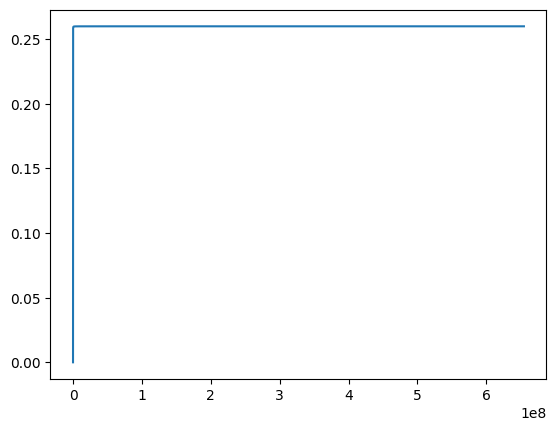

In [77]:
# plt.plot(z_jax, h_interp(z_jax)/h_interp_jax(z_jax))
plt.plot(z, (h_interp(z)-h_interp_jax(z))/h_interp(z))

In [27]:
def _vector_field(x, y, args):
    cp, da, dcp = y
    omega_m, h, OmL, stigma, mups2 = args
    a = jnp.exp(x)
    fac = a / da                              # dtau/dx
    return (dcp * fac,
            dda(a, da, cp, dcp, omega_m, h, OmL, stigma, mups2) * fac,
            ddcp(a, da, cp, dcp, omega_m, h, OmL, stigma, mups2) * fac)

array([-3.87768324e-02, -3.88935074e-02, -3.90104195e-02, ...,
       -1.07001376e+08, -9.63829120e+07, -8.20828160e+07], shape=(10000,))

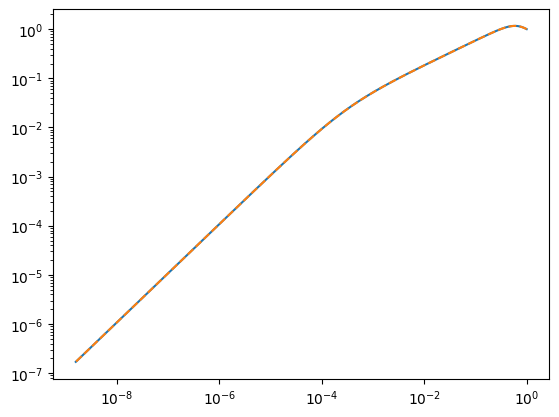

In [52]:
import matplotlib.pyplot as plt
a = 1/(1+z)
a_jax = 1/(1+z_jax)
plt.plot(a, 0.7*100/(a*(H)))
plt.plot(a_jax, 0.7*100/(a_jax*(H_jax)), "--")
plt.xscale("log")
plt.yscale("log")

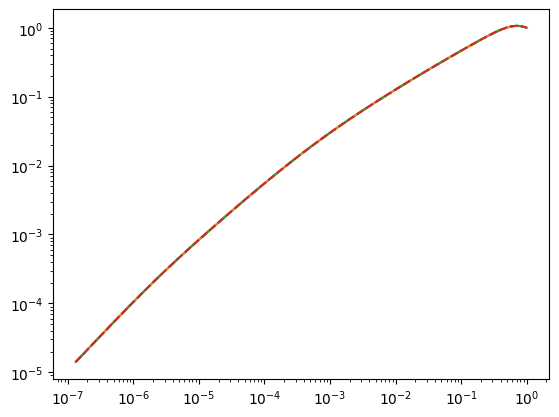

In [108]:
plt.plot(asol, H_NORM*100/(asol*(H_sol)))
plt.plot(asol, H_NORM*100/(asol*((a0* hsol)/asol**2)))
plt.plot(asol2, H_NORM*100/(asol2*(H_arr[::-1])), "-.")
plt.plot(asol2, H_NORM*100/(asol2*((a02* hsol2)/asol2**2)), '--')
plt.xscale("log")
plt.yscale("log")

In [109]:
def compute_desi_distances(asol, H_sol, rd):
    """
    Compute DESI DR2 BAO distances from the physical Hubble array.

    H_sol = a0 * hsol / a²  (physical Hubble in km/s/Mpc, from solve_stigma_jax).
    rd    should come from get_rd_camb for a theory-consistent sound horizon.

    DH(z)/rd = c / (H(z) * rd)
    DM(z)/rd = (c/rd) * ∫_{a(z)}^{1} da / (a² H(a))
    DV(z)/rd = (z * DM² * DH)^{1/3} / rd

    Returns
    -------
    theory : array shape (13,) matching desidr2_mean.txt row order
    """
    z_all = jnp.array([0.295, 0.510, 0.510, 0.706, 0.706,
                        0.934, 0.934, 1.321, 1.321, 1.484, 1.484, 2.330, 2.330])
    a_all = 1.0 / (1.0 + z_all)

    # ── DH(z)/rd = c / (H(z) * rd) ────────────────────────────────────────
    H_at_a     = jnp.interp(a_all, asol, H_sol)
    DH_over_rd = C_KMS / (H_at_a * rd)

    # ── DM(z)/rd = (c/rd) ∫_{a(z)}^{1} da/(a² H(a)) ──────────────────────
    integrand  = 1.0 / (asol**2 * H_sol)
    da_arr     = jnp.diff(asol)
    trap_terms = 0.5 * (integrand[:-1] + integrand[1:]) * da_arr
    cum_int    = jnp.concatenate([jnp.array([0.0]), jnp.cumsum(trap_terms)])

    cum_at_1   = jnp.interp(jnp.array(1.0), asol, cum_int)
    cum_at_az  = jnp.interp(a_all, asol, cum_int)
    DM_over_rd = C_KMS / rd * (cum_at_1 - cum_at_az)

    # ── DV(z)/rd ───────────────────────────────────────────────────────────
    DV_over_rd = (z_all * DM_over_rd**2 * DH_over_rd)**(1.0/3.0)

    theory = jnp.array([
        DV_over_rd[0],
        DM_over_rd[1],  DH_over_rd[2],
        DM_over_rd[3],  DH_over_rd[4],
        DM_over_rd[5],  DH_over_rd[6],
        DM_over_rd[7],  DH_over_rd[8],
        DM_over_rd[9],  DH_over_rd[10],
        DM_over_rd[11], DH_over_rd[12],
    ])
    return theory